# Assignment 4 Evaluating FairSHAP
Ahmed Amer · 9472428

This notebook evaluates **FairSHAP** on German Credit, COMPAS and Adult. I first measure fairness in the original labels, then compare an ordinary XGBoost classifier with one retrained after FairSHAP preprocessing. Both classifiers are tested on exactly the same untouched hold-out examples.

The aim is a small, readable implementation of the paper's method, rather than a reproduction of every experiment. The paper uses five-fold cross-validation and KernelSHAP; here I use one stratified 80/20 split and 16 sampled feature orders to estimate the same Shapley contributions. I keep all available rows. No parameter is chosen using the test results.

Paper: [Zhu, Bian and You (2026)](https://proceedings.mlr.press/v300/zhu26b.html). Original implementation: [FairSHAP](https://github.com/lin1zhu0216/FairSHAP).

**Observed result.** FairSHAP reduced mean discriminative risk on all three test sets. The demographic-parity gap improved on COMPAS (0.1752 to 0.1280) and Adult (0.1799 to 0.1673), but worsened on German Credit (0.0519 to 0.0858). Accuracy changed by +0.50, −0.69 and −0.12 percentage points, respectively. This run supports the method's targeted effect on DR, but shows that the group-fairness benefit is not automatic.

## 1 Setup
Use **Python 3.12** in a notebook app, such as VS Code with Jupyter support or JupyterLab. Download the repository ZIP, extract it, open the extracted folder, and open this notebook. Select a Python 3.12 kernel and choose **Run All**. No terminal commands are needed.

The first code cell automatically installs any missing or different package versions into the selected Python environment. This needs an internet connection on the first run and may take a few minutes. The datasets and completed results are included in the ZIP. Subsequent cells explain the experiment as it runs.

`N_PERMUTATIONS` controls the cost of Shapley estimation; increasing it reduces sampling noise but takes longer. `THRESHOLD` is the paper's default. All other experimental settings are fixed below.

In [1]:
# Run this cell first. Package setup is automatic; no terminal is needed.
import sys
import subprocess
import importlib
import importlib.util
from importlib import metadata
from pathlib import Path

if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select a Python 3.12 notebook kernel, then choose Run All again.")

candidate_folders = [Path.cwd(), Path.cwd() / "fairshap-implementation"]
candidate_folders += list(Path.cwd().glob("DW-Assignment-4-FairSHAP*"))
ROOT = next((folder for folder in candidate_folders
             if (folder / "requirements.txt").is_file()
             and (folder / "Assignment 4 FairSHAP.ipynb").is_file()), None)
if ROOT is None:
    raise RuntimeError("Extract the whole ZIP and open its extracted project folder in your notebook app.")

required = [line.strip() for line in (ROOT / "requirements.txt").read_text().splitlines()
            if line.strip() and not line.startswith("#")]
to_install = []
for requirement in required:
    package, pinned_version = requirement.split("==")
    try:
        installed_version = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed_version = None
    if installed_version != pinned_version:
        to_install.append(requirement)

if to_install:
    print(f"Setting up {len(to_install)} package(s) in the selected Python environment. Please wait...", flush=True)
    if importlib.util.find_spec("pip") is None:
        subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"],
                       check=True, capture_output=True, text=True)
    installed = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet",
         "--disable-pip-version-check", *to_install],
        capture_output=True, text=True,
    )
    if installed.returncode:
        print(installed.stderr[-2000:])
        raise RuntimeError("Package setup failed. Check your internet connection and Python 3.12 kernel, then rerun this cell.")
    importlib.invalidate_caches()
    print("Package setup complete. Continuing with the experiment.")
else:
    print("Python 3.12 is ready; all required package versions are installed.")

Setting up 1 package(s) in the selected Python environment. Please wait...


Package setup complete. Continuing with the experiment.


In [2]:
from pathlib import Path
from urllib.request import urlopen
import hashlib, json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
from IPython.display import display

SEED = 42
TEST_SIZE = 0.20
N_PERMUTATIONS = 16
THRESHOLD = 0.05
K_NEIGHBORS = 5
# ROOT was located by the automatic setup cell.
DATA = ROOT / "data"
RESULTS = ROOT / "results"
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.8),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(
    {
        "Python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "xgboost": xgboost.__version__,
    }
)

{'Python': '3.12.14', 'numpy': '2.3.5', 'pandas': '3.0.1', 'sklearn': '1.9.1', 'xgboost': '3.4.1'}


## 2 Download and prepare the three datasets
German Credit and COMPAS are downloaded from the authors' repository at a fixed commit, so their starting files match the released implementation. COMPAS originates from ProPublica; Adult is downloaded directly from UCI. The files are cached locally and their SHA-256 hashes are saved for provenance.

I use **sex** as the sensitive attribute in all three datasets: female = 0 and male = 1. A favourable label of 1 means good credit, no recorded two-year recidivism, or income above $50,000. The German and COMPAS labels are therefore the complements of the authors' coding. This makes the disparate-impact ratio easier to interpret. Absolute DP and accuracy have the same definitions after consistently complementing outcomes, although separate training runs need not produce exactly complementary predictions.

The selected features follow the authors' loaders. Adult's `?` entries remain an explicit category, as in their code. German account fields are imputed using the most frequent training value. Numerical values are standardised and categories are one-hot encoded. For modelling, every fitted preprocessing step uses training rows only.

In [3]:
UPSTREAM_COMMIT = "d070e24d7295d31444f64d84f932c5ece5e3456a"
SOURCES = {
    "german_credit.csv": f"https://raw.githubusercontent.com/lin1zhu0216/FairSHAP/{UPSTREAM_COMMIT}/dataset/german_credit/german_credit.csv",
    "compas.csv": f"https://raw.githubusercontent.com/lin1zhu0216/FairSHAP/{UPSTREAM_COMMIT}/dataset/compas/compas-scores-two-years.csv",
    "adult.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
}
source_records = []
for filename, url in SOURCES.items():
    path = DATA / filename
    if not path.exists():
        with urlopen(url, timeout=60) as response:
            path.write_bytes(response.read())
    source_records.append(
        {
            "file": filename,
            "url": url,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
    )

german = pd.read_csv(DATA / "german_credit.csv")
german_x = german.drop(columns="Risk").rename(columns={"Sex": "sex"})
german_x["sex"] = german_x["sex"].map({"female": 0, "male": 1})
german_y = (german["Risk"] == "good").astype(int)

compas = pd.read_csv(DATA / "compas.csv")
compas_columns = [
    "sex",
    "age",
    "race",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "priors_count",
    "c_charge_degree",
    "score_text",
    "type_of_assessment",
]
compas_x = compas[compas_columns].copy()
compas_x["sex"] = compas_x["sex"].map({"Female": 0, "Male": 1})
compas_y = 1 - compas["two_year_recid"].astype(int)

adult_columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income",
]
adult = pd.read_csv(DATA / "adult.data", names=adult_columns, skipinitialspace=True)
adult_x = adult.drop(columns=["income", "fnlwgt"]).copy()
adult_x["sex"] = adult_x["sex"].map({"Female": 0, "Male": 1})
adult_y = (adult["income"] == ">50K").astype(int)

datasets = {
    "German Credit": (german_x, german_y, ["Age", "Credit amount", "Duration"]),
    "COMPAS": (
        compas_x,
        compas_y,
        ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"],
    ),
    "Adult": (
        adult_x,
        adult_y,
        ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"],
    ),
}


def make_preprocessor(frame, numeric_columns):
    categorical = [c for c in frame.columns if c not in numeric_columns + ["sex"]]
    return ColumnTransformer(
        [
            ("numbers", StandardScaler(), numeric_columns),
            (
                "categories",
                make_pipeline(
                    SimpleImputer(strategy="most_frequent"),
                    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                ),
                categorical,
            ),
            ("sensitive", "passthrough", ["sex"]),
        ],
        sparse_threshold=0,
    )


data_overview = pd.DataFrame(
    [
        {
            "Dataset": name,
            "Rows": len(frame),
            "Raw predictors": frame.shape[1],
            "Female": int((frame.sex == 0).sum()),
            "Male": int((frame.sex == 1).sum()),
            "Favourable labels": float(labels.mean()),
        }
        for name, (frame, labels, _) in datasets.items()
    ]
)
assert data_overview.Rows.tolist() == [1000, 7214, 32561]
assert all(set(frame.sex.unique()) == {0, 1} for frame, _, _ in datasets.values())
display(data_overview)

,Dataset,Rows,Raw predictors,Female,Male,Favourable labels
0,German Credit,1000,9,310,690,0.7000
1,COMPAS,7214,10,1395,5819,0.5493
2,Adult,32561,13,10771,21790,0.2408


## 3 Measure fairness in the original labels
For each dataset, let $p_0$ and $p_1$ be the favourable-outcome rates among female and male records.

* **DP_Diff** = $|p_0-p_1|$. Zero means equal rates. I also save the signed difference $p_0-p_1$.
* **DIR** = $p_0/p_1$. One means equal rates; values above one favour the female group under this coding. It is not capped at one.
* **Consistency** = $1-\frac{1}{n}\sum_i|y_i-\frac{1}{5}\sum_{j\in N_5(i)}y_j|$. Higher means more similar labels among nearby records. I use Euclidean distance after encoding/scaling, exclude sex from the distance, and allow self matches, following AIF360’s convention.

The following table uses the **original labels of every available row**, before fitting any classifier. The encoder and scaler here only define distances for this descriptive check. A separate preprocessor will be fitted on training rows for the actual experiment. Original-label scores and test-prediction scores describe different populations and outcomes; the baseline-versus-FairSHAP comparison on the same test rows isolates the pipeline difference.

In [4]:
def neighbour_indices(features, k=K_NEIGHBORS):
    # Sex is the last encoded column; label values never enter the distance.
    space = np.asarray(features[:, :-1], dtype=np.float64)
    return (
        NearestNeighbors(n_neighbors=k, algorithm="brute", n_jobs=4)
        .fit(space)
        .kneighbors(space, return_distance=False)
    )


def fairness_metrics(outcomes, sensitive, neighbours):
    outcomes = np.asarray(outcomes, dtype=float)
    sensitive = np.asarray(sensitive)
    female_rate = outcomes[sensitive == 0].mean()
    male_rate = outcomes[sensitive == 1].mean()
    return {
        "DP_Diff": float(abs(female_rate - male_rate)),
        "DP_signed": float(female_rate - male_rate),
        "DIR": float(female_rate / male_rate) if male_rate else np.nan,
        "Consistency": float(
            1 - np.abs(outcomes - outcomes[neighbours].mean(axis=1)).mean()
        ),
        "Female_rate": float(female_rate),
        "Male_rate": float(male_rate),
    }


original_rows = []
for name, (frame, labels, numeric) in datasets.items():
    original_features = (
        make_preprocessor(frame, numeric).fit_transform(frame).astype(np.float32)
    )
    values = fairness_metrics(labels, frame.sex, neighbour_indices(original_features))
    original_rows.append({"Dataset": name, **values})
original_metrics = pd.DataFrame(original_rows)
display(original_metrics[["Dataset", "DP_Diff", "DIR", "Consistency"]])
original_metrics.to_csv(RESULTS / "original_label_metrics.csv", index=False)

,Dataset,DP_Diff,DIR,Consistency
0,German Credit,0.0748,0.8966,0.6952
1,COMPAS,0.1161,1.2204,0.6627
2,Adult,0.1963,0.3580,0.8405


## 4 Implement FairSHAP
FairSHAP is a **preprocessing** method. A preliminary classifier guides edits to the training features; a fresh classifier is then fitted on those edited rows.

For each training row I find its nearest row with the **same label and opposite sex**. Matching in both directions provides one reference per row. I store the reference index directly instead of constructing the authors' dense matching-probability matrix; with one nearest neighbour this represents the same deterministic match.

I then ask how each feature changes discriminative risk, $DR(x)=|f(x,A=0)-f(x,A=1)|$. Start at the reference, replace its feature values with the row's own values one at a time, and record each resulting change in DR. Averaging a feature's changes over sampled orders estimates its Shapley attribution. The orders are paired with their reverses to use the fixed sampling budget more effectively. This replaces the authors' KernelSHAP estimator; the attribution target and feature-replacement rule stay the same.

Finally, every non-sensitive feature whose attribution is at least 0.05 is replaced by its reference value. The label, sex and row count are preserved. I do this once and retrain once; I do not search over edit counts using the test set.

In [5]:
def new_classifier():
    return XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.3,
        objective="binary:logistic",
        tree_method="hist",
        n_jobs=4,
        random_state=SEED,
        eval_metric="logloss",
    )


def discriminative_risk(model, features):
    female = features.copy()
    male = features.copy()
    female[:, -1] = 0
    male[:, -1] = 1
    return np.abs(model.predict_proba(female)[:, 1] - model.predict_proba(male)[:, 1])


def match_references(features, labels):
    labels = np.asarray(labels)
    sex = features[:, -1]
    reference_indices = np.empty(len(features), dtype=int)
    for label in [0, 1]:
        for group in [0, 1]:
            target = np.flatnonzero((labels == label) & (sex == group))
            reference = np.flatnonzero((labels == label) & (sex != group))
            nearest = NearestNeighbors(n_neighbors=1, algorithm="brute", n_jobs=4)
            nearest.fit(features[reference, :-1])
            matches = nearest.kneighbors(features[target, :-1], return_distance=False)[
                :, 0
            ]
            reference_indices[target] = reference[matches]
    assert np.all(labels == labels[reference_indices])
    assert np.all(sex != sex[reference_indices])
    references = features[reference_indices].copy()
    references[:, -1] = sex  # DR does not depend on the input's original sex value.
    return references, reference_indices


def permutation_shapley(model, features, references, n_orders=N_PERMUTATIONS):
    rng = np.random.default_rng(SEED)
    orders = []
    while len(orders) < n_orders:
        order = rng.permutation(features.shape[1] - 1)
        orders.extend([order, order[::-1]])
    contributions = np.zeros_like(features, dtype=np.float64)
    reference_dr = discriminative_risk(model, references)
    for order_number, order in enumerate(orders[:n_orders], start=1):
        current = references.copy()
        previous_dr = reference_dr
        for feature in order:
            current[:, feature] = features[:, feature]
            next_dr = discriminative_risk(model, current)
            contributions[:, feature] += next_dr - previous_dr
            previous_dr = next_dr
        if order_number % 4 == 0:
            print(f"  Shapley orders {order_number}/{n_orders}", flush=True)
    contributions /= n_orders
    # Each complete path telescopes from reference DR to target DR.
    expected_change = discriminative_risk(model, features) - reference_dr
    np.testing.assert_allclose(contributions.sum(axis=1), expected_change, atol=2e-6)
    return contributions


def fairshap_preprocess(model, features, labels):
    references, indices = match_references(features, labels)
    attributions = permutation_shapley(model, features, references)
    selected = attributions >= THRESHOLD
    selected[:, -1] = False
    changed = features.copy()
    changed[selected] = references[selected]
    np.testing.assert_array_equal(changed[:, -1], features[:, -1])
    assert changed.shape == features.shape
    return changed, attributions, indices, selected

## 5 Train and evaluate on untouched test data
The split is stratified jointly by label and sex, which preserves their four combinations. The preprocessor is fitted on training rows only. Both classifiers use the same fixed XGBoost settings and a 0.5 decision threshold. The test features are never edited.

Besides the assignment's metrics, I report mean DR to check the fairness measure FairSHAP directly targets. The small assertion inside the estimator verifies that the attributions sum to the difference between each row's DR and its reference's DR. This checks the estimator's accounting; it does not prove that a 16-order estimate is exact.

In [6]:
test_rows, run_rows = [], []
for name, (frame, labels, numeric) in datasets.items():
    started = time.perf_counter()
    print(f"Running {name} ({len(frame):,} rows)", flush=True)
    train_ids, test_ids = train_test_split(
        np.arange(len(frame)),
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=labels.astype(str) + "_" + frame.sex.astype(str),
    )
    processor = make_preprocessor(frame, numeric)
    train_x = processor.fit_transform(frame.iloc[train_ids]).astype(np.float32)
    test_x = processor.transform(frame.iloc[test_ids]).astype(np.float32)
    train_y, test_y = (
        labels.iloc[train_ids].to_numpy(),
        labels.iloc[test_ids].to_numpy(),
    )
    test_neighbours = neighbour_indices(test_x)

    baseline = new_classifier().fit(train_x, train_y)
    changed_x, attributions, matches, selected = fairshap_preprocess(
        baseline, train_x, train_y
    )
    mitigated = new_classifier().fit(changed_x, train_y)
    predictions = {}
    for method, model in [("Baseline", baseline), ("FairSHAP", mitigated)]:
        predicted = model.predict(test_x)
        predictions[method] = predicted
        values = fairness_metrics(predicted, frame.sex.iloc[test_ids], test_neighbours)
        test_rows.append(
            {
                "Dataset": name,
                "Method": method,
                **values,
                "Accuracy": float(accuracy_score(test_y, predicted)),
                "DR": float(discriminative_risk(model, test_x).mean()),
            }
        )

    actual_changes = int(np.count_nonzero(changed_x != train_x))
    run_rows.append(
        {
            "Dataset": name,
            "Train": len(train_ids),
            "Test": len(test_ids),
            "Encoded_features": train_x.shape[1],
            "Selected_cells": int(selected.sum()),
            "Changed_cells": actual_changes,
            "Changed_percent": 100
            * actual_changes
            / (train_x.shape[0] * (train_x.shape[1] - 1)),
            "Seconds": time.perf_counter() - started,
        }
    )
    print(
        f"  Finished in {run_rows[-1]['Seconds']:.1f} s; {actual_changes:,} cells changed",
        flush=True,
    )

test_metrics = pd.DataFrame(test_rows)
run_details = pd.DataFrame(run_rows)
display(
    test_metrics[
        ["Dataset", "Method", "DP_Diff", "DIR", "Consistency", "Accuracy", "DR"]
    ]
)
display(
    run_details[
        ["Dataset", "Train", "Test", "Encoded_features", "Changed_percent", "Seconds"]
    ].rename(
        columns={
            "Encoded_features": "Features",
            "Changed_percent": "Cells changed (%)",
            "Seconds": "Time (s)",
        }
    )
)
test_metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
run_details.to_csv(RESULTS / "run_details.csv", index=False)
provenance = {
    "seed": SEED,
    "test_size": TEST_SIZE,
    "n_permutations": N_PERMUTATIONS,
    "threshold": THRESHOLD,
    "k_neighbors": K_NEIGHBORS,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "sources": source_records,
    "upstream_commit": UPSTREAM_COMMIT,
}
_ = (RESULTS / "provenance.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

Running German Credit (1,000 rows)


  Shapley orders 4/16


  Shapley orders 8/16


  Shapley orders 12/16


  Shapley orders 16/16


  Finished in 1.2 s; 316 cells changed


... (10 outputs left out)

  Shapley orders 16/16


  Finished in 79.0 s; 3,558 cells changed


,Dataset,Method,DP_Diff,DIR,Consistency,Accuracy,DR
0,German Credit,Baseline,0.0519,0.9372,0.8100,0.7100,0.0652
1,German Credit,FairSHAP,0.0858,0.8943,0.7930,0.7150,0.0315
2,COMPAS,Baseline,0.1752,1.2944,0.8687,0.6701,0.0973
3,COMPAS,FairSHAP,0.1280,1.2060,0.8531,0.6632,0.0632
4,Adult,Baseline,0.1799,0.3231,0.9289,0.8693,0.0353
5,Adult,FairSHAP,0.1673,0.3380,0.9312,0.8681,0.0332


,Dataset,Train,Test,Features,Cells changed (%),Time (s)
0,German Credit,800,200,26,1.5800,1.1897
1,COMPAS,5771,1443,18,1.2904,2.4842
2,Adult,26048,6513,106,0.1301,79.0440


## 6 Compare with the paper
The published values below are decision-based demographic-parity gaps for sex from the paper's Table 1. Lower is better. The paper reports five-fold means; my numbers come from one held-out split and a different Shapley estimator. I therefore compare the direction and scale of the change, rather than claim an exact replication. The authors also use different outcome coding for German Credit and COMPAS. Neither DIR nor consistency is reported in the paper, so no published value is invented for them.

,Dataset,Paper baseline DP,Paper FairSHAP DP,My baseline DP,My FairSHAP DP,Paper change,My change
0,German Credit,0.0512,0.0301,0.0519,0.0858,-0.0211,0.0339
1,COMPAS,0.1548,0.1326,0.1752,0.1280,-0.0222,-0.0473
2,Adult,0.1805,0.1558,0.1799,0.1673,-0.0247,-0.0126


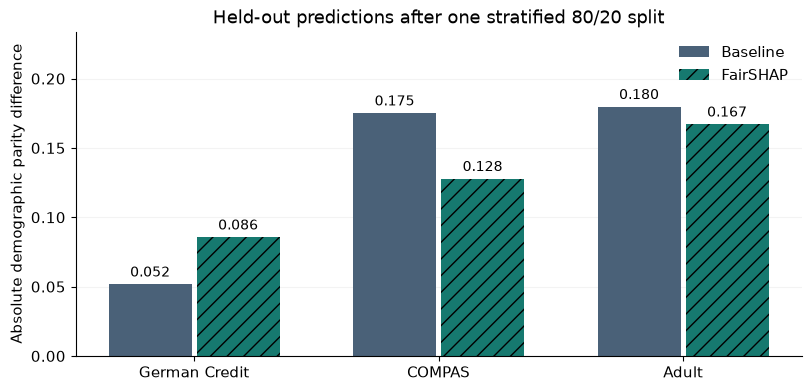

In [7]:
published = pd.DataFrame(
    {
        "Dataset": ["German Credit", "COMPAS", "Adult"],
        "Paper baseline DP": [0.0512, 0.1548, 0.1805],
        "Paper FairSHAP DP": [0.0301, 0.1326, 0.1558],
    }
)
local_dp = test_metrics.pivot(
    index="Dataset", columns="Method", values="DP_Diff"
).reset_index()
comparison = published.merge(local_dp, on="Dataset").rename(
    columns={"Baseline": "My baseline DP", "FairSHAP": "My FairSHAP DP"}
)
comparison["Paper change"] = (
    comparison["Paper FairSHAP DP"] - comparison["Paper baseline DP"]
)
comparison["My change"] = comparison["My FairSHAP DP"] - comparison["My baseline DP"]
display(comparison)
comparison.to_csv(RESULTS / "paper_comparison.csv", index=False)

fig, ax = plt.subplots(layout="constrained")
x = np.arange(len(comparison))
for offset, method, color, hatch in [
    (-0.18, "Baseline", "#4a6178", ""),
    (0.18, "FairSHAP", "#16796f", "//"),
]:
    values = comparison[f"My {method.lower() if method == 'Baseline' else method} DP"]
    bars = ax.bar(
        x + offset, values, width=0.34, label=method, color=color, hatch=hatch
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=10)
ax.set(
    xticks=x,
    xticklabels=comparison.Dataset,
    ylabel="Absolute demographic parity difference",
    title="Held-out predictions after one stratified 80/20 split",
)
ax.set_ylim(0, max(comparison[["My baseline DP", "My FairSHAP DP"]].max()) * 1.3)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
plt.show()

## 7 Interpretation
The results answer two different questions. The original-label table shows existing disparities in the datasets. To assess the mitigation pipeline itself, the baseline and FairSHAP rows compare predictions on exactly the same held-out people.

**German Credit:** mean DR fell from 0.0652 to 0.0315, but DP increased from 0.0519 to 0.0858 and consistency fell from 0.8100 to 0.7930. Accuracy rose by 0.50 percentage points. Reducing sensitivity to sex did not produce more equal group outcomes in this split.

**COMPAS:** DP fell from 0.1752 to 0.1280 and DIR moved closer to one (1.2944 to 1.2060). Accuracy fell by 0.69 percentage points, and consistency also fell. The favourable outcome is no recorded recidivism, so the female/male favourable-outcome ratio exceeds one in these data.

**Adult:** DP fell from 0.1799 to 0.1673 and consistency increased slightly. DIR improved from 0.3231 to 0.3380, but a sizeable disparity remains. Accuracy fell by 0.12 percentage points.

The paper reports lower DP after mitigation on all three datasets, whereas my German result goes the other way. My single split, finite permutation budget, train-only preprocessing, different outcome coding and newer software prevent an exact comparison with its five-fold results. I do not tune the threshold to remove this disagreement. DR, group parity and neighbour consistency capture different forms of fairness; no single measure establishes that a model is fair overall.

In [8]:
for name in published.Dataset:
    rows = test_metrics.set_index(["Dataset", "Method"])
    before, after = rows.loc[(name, "Baseline")], rows.loc[(name, "FairSHAP")]
    print(
        f"{name}: DP {before.DP_Diff:.4f} → {after.DP_Diff:.4f}; "
        f"DIR {before.DIR:.4f} → {after.DIR:.4f}; "
        f"consistency {before.Consistency:.4f} → {after.Consistency:.4f}; "
        f"accuracy change {(after.Accuracy-before.Accuracy)*100:+.2f} percentage points."
    )

German Credit: DP 0.0519 → 0.0858; DIR 0.9372 → 0.8943; consistency 0.8100 → 0.7930; accuracy change +0.50 percentage points.
COMPAS: DP 0.1752 → 0.1280; DIR 1.2944 → 1.2060; consistency 0.8687 → 0.8531; accuracy change -0.69 percentage points.
Adult: DP 0.1799 → 0.1673; DIR 0.3231 → 0.3380; consistency 0.9289 → 0.9312; accuracy change -0.12 percentage points.


## References
* Zhu, L., Bian, Y. and You, L. (2026). [FairSHAP: Preprocessing for Fairness Through Attribution-Based Data Augmentation](https://proceedings.mlr.press/v300/zhu26b.html). AISTATS, PMLR 300, 2773–2781.
* Authors' [implementation and data loaders](https://github.com/lin1zhu0216/FairSHAP/tree/d070e24d7295d31444f64d84f932c5ece5e3456a), inspected to match features and the matching/replacement procedure. The short implementation above is independently written, using sampled permutation contributions in place of KernelSHAP.
* [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult), [UCI German Credit](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data), and [ProPublica COMPAS analysis](https://github.com/propublica/compas-analysis).
* [AIF360 binary-label metrics](https://aif360.readthedocs.io/en/stable/modules/generated/aif360.metrics.BinaryLabelDatasetMetric.html), for disparate impact and the consistency formula. Here DP_Diff is absolute, and the consistency distance excludes the sensitive attribute.